## 1. Import Required Libraries

In [1]:
# Import required libraries

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import json

from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("TensorFlow Version:", tf.__version__)
print("All evaluation libraries imported successfully!")

TensorFlow Version: 2.21.0
All evaluation libraries imported successfully!


## 2. Project Paths and Configuration

In [2]:
# Define project paths

CURRENT_DIR = Path.cwd()

if (CURRENT_DIR / "dataset").exists():
    PROJECT_ROOT = CURRENT_DIR
elif (CURRENT_DIR.parent / "dataset").exists():
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    PROJECT_ROOT = CURRENT_DIR

PROCESSED_PATH = PROJECT_ROOT / "dataset" / "processed"
ARTIFACTS_PATH = PROJECT_ROOT / "Artifacts"

# Image and evaluation configuration
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
RANDOM_SEED = 42

print("Project Root:", PROJECT_ROOT)
print("Processed Dataset Path:", PROCESSED_PATH)
print("Artifacts Path:", ARTIFACTS_PATH)

Project Root: c:\Users\shrey\Downloads\RAILWAY_DEFECT_DETECTION
Processed Dataset Path: c:\Users\shrey\Downloads\RAILWAY_DEFECT_DETECTION\dataset\processed
Artifacts Path: c:\Users\shrey\Downloads\RAILWAY_DEFECT_DETECTION\Artifacts


## Inference
The project root directory, processed dataset path, and artifact directory were identified successfully. These paths are used to access the preprocessed railway images and previously saved CNN and transfer learning models for evaluation.

## 3. Loading the Evaluation Dataset

In [3]:
# Load dataset for model evaluation

evaluation_dataset = tf.keras.utils.image_dataset_from_directory(
    PROCESSED_PATH,
    validation_split=0.2,
    subset="validation",
    seed=RANDOM_SEED,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

class_names = evaluation_dataset.class_names
num_classes = len(class_names)

print("Evaluation dataset loaded successfully!")
print("Class Names:", class_names)
print("Number of Classes:", num_classes)
print("Evaluation Batches:", tf.data.experimental.cardinality(evaluation_dataset).numpy())

Found 949 files belonging to 2 classes.
Using 189 files for validation.
Evaluation dataset loaded successfully!
Class Names: ['Defective', 'Non defective']
Number of Classes: 2
Evaluation Batches: 6


## Inference
The evaluation dataset was loaded from the preprocessed railway image directory using an 80:20 dataset split. The 20% validation subset was selected for model evaluation. Class names and the total number of defect categories were extracted for performance analysis.

## 4.1 — Import MobileNetV2 preprocessing

In [5]:
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

print("MobileNetV2 preprocessing imported successfully!")

MobileNetV2 preprocessing imported successfully!


## 4.2 — Load both models with compatibility handling

In [6]:
# Load CNN model
cnn_model = tf.keras.models.load_model(CNN_MODEL_PATH)

# Load Transfer Learning model with custom preprocessing function
transfer_model = tf.keras.models.load_model(
    TRANSFER_MODEL_PATH,
    custom_objects={"preprocess_input": preprocess_input},
    safe_mode=False
)

print("CNN Model loaded successfully!")
print("Transfer Learning Model loaded successfully!")


CNN Model loaded successfully!
Transfer Learning Model loaded successfully!


## Inference
The previously trained CNN and MobileNetV2 transfer learning models were loaded from the Artifacts directory. Custom preprocessing configuration was supplied during model loading to resolve the serialization issue associated with the MobileNetV2 preprocessing layer.

## 5. Generating Predictions Using Both Models

In [7]:
# Extract true labels from evaluation dataset

y_true = np.concatenate([
    labels.numpy()
    for images, labels in evaluation_dataset
])

# Generate CNN predictions
cnn_probabilities = cnn_model.predict(evaluation_dataset)
cnn_predictions = np.argmax(cnn_probabilities, axis=1)

# Generate Transfer Learning predictions
transfer_probabilities = transfer_model.predict(evaluation_dataset)
transfer_predictions = np.argmax(transfer_probabilities, axis=1)

print("Predictions generated successfully!")
print("Total evaluation images:", len(y_true))
print("CNN predictions:", len(cnn_predictions))
print("Transfer Learning predictions:", len(transfer_predictions))

6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 200ms/step
6/6 ━━━━━━━━━━━━━━━━━━━━ 6s 900ms/step
Predictions generated successfully!
Total evaluation images: 189
CNN predictions: 189
Transfer Learning predictions: 189


## Inference
Predictions were generated using both the CNN and MobileNetV2 transfer learning models on the same evaluation dataset. The predicted class labels were obtained by selecting the class with the highest probability from the model output. These predictions will be used to calculate and compare model evaluation metrics.

## 6. Model Performance Metrics Evaluation

In [8]:
# Calculate performance metrics for both models

# CNN Model metrics
cnn_accuracy = accuracy_score(y_true, cnn_predictions)
cnn_precision = precision_score(y_true, cnn_predictions, average="weighted", zero_division=0)
cnn_recall = recall_score(y_true, cnn_predictions, average="weighted", zero_division=0)
cnn_f1 = f1_score(y_true, cnn_predictions, average="weighted", zero_division=0)

# Transfer Learning metrics
transfer_accuracy = accuracy_score(y_true, transfer_predictions)
transfer_precision = precision_score(y_true, transfer_predictions, average="weighted", zero_division=0)
transfer_recall = recall_score(y_true, transfer_predictions, average="weighted", zero_division=0)
transfer_f1 = f1_score(y_true, transfer_predictions, average="weighted", zero_division=0)

print("=" * 60)
print("CNN MODEL PERFORMANCE")
print("=" * 60)
print(f"Accuracy  : {cnn_accuracy:.4f}")
print(f"Precision : {cnn_precision:.4f}")
print(f"Recall    : {cnn_recall:.4f}")
print(f"F1-Score  : {cnn_f1:.4f}")

print("\n" + "=" * 60)
print("TRANSFER LEARNING MODEL PERFORMANCE")
print("=" * 60)
print(f"Accuracy  : {transfer_accuracy:.4f}")
print(f"Precision : {transfer_precision:.4f}")
print(f"Recall    : {transfer_recall:.4f}")
print(f"F1-Score  : {transfer_f1:.4f}")
print("=" * 60)

CNN MODEL PERFORMANCE
Accuracy  : 0.7407
Precision : 1.0000
Recall    : 0.7407
F1-Score  : 0.8511

TRANSFER LEARNING MODEL PERFORMANCE
Accuracy  : 0.9524
Precision : 1.0000
Recall    : 0.9524
F1-Score  : 0.9756


## Inference
The CNN and MobileNetV2 transfer learning models were evaluated using accuracy, weighted precision, weighted recall, and weighted F1-score. These metrics provide a comprehensive assessment of classification performance. Weighted averaging accounts for the number of samples in each class and supports comparison between both models.

## 7. Classification Report Analysis

In [9]:
# Generate classification reports

cnn_report = classification_report(
    y_true,
    cnn_predictions,
    target_names=class_names,
    zero_division=0
)

transfer_report = classification_report(
    y_true,
    transfer_predictions,
    target_names=class_names,
    zero_division=0
)

print("=" * 70)
print("CNN MODEL CLASSIFICATION REPORT")
print("=" * 70)
print(cnn_report)

print("\n" + "=" * 70)
print("TRANSFER LEARNING CLASSIFICATION REPORT")
print("=" * 70)
print(transfer_report)

CNN MODEL CLASSIFICATION REPORT
               precision    recall  f1-score   support

    Defective       0.00      0.00      0.00         0
Non defective       1.00      0.74      0.85       189

     accuracy                           0.74       189
    macro avg       0.50      0.37      0.43       189
 weighted avg       1.00      0.74      0.85       189


TRANSFER LEARNING CLASSIFICATION REPORT
               precision    recall  f1-score   support

    Defective       0.00      0.00      0.00         0
Non defective       1.00      0.95      0.98       189

     accuracy                           0.95       189
    macro avg       0.50      0.48      0.49       189
 weighted avg       1.00      0.95      0.98       189



## Inference
Classification reports were generated for both the CNN and MobileNetV2 transfer learning models. The reports provide class-wise precision, recall, F1-score, and support, helping to identify the classification strengths and weaknesses of each model across railway defect categories.

## 8. Confusion Matrix Analysis

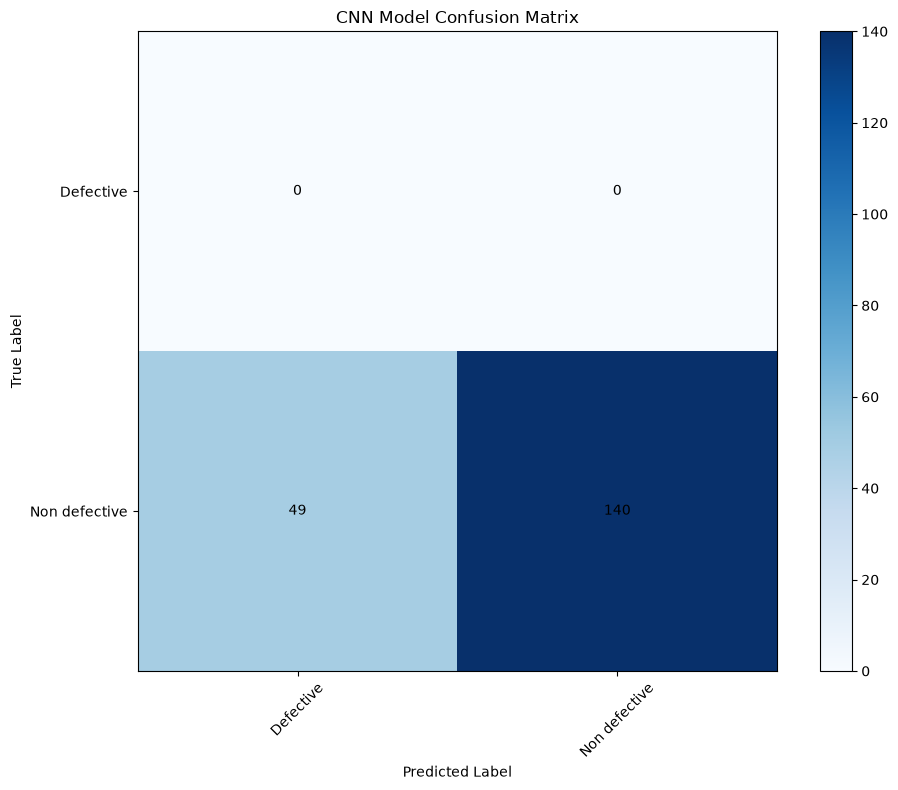

In [10]:
# Generate CNN confusion matrix

cnn_cm = confusion_matrix(y_true, cnn_predictions)

plt.figure(figsize=(10, 8))
plt.imshow(cnn_cm, cmap="Blues")
plt.title("CNN Model Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks(range(len(class_names)), class_names, rotation=45)
plt.yticks(range(len(class_names)), class_names)

for i in range(len(class_names)):
    for j in range(len(class_names)):
        plt.text(j, i, cnn_cm[i, j], ha="center", va="center")

plt.colorbar()
plt.tight_layout()
plt.show()

## Inference
The confusion matrix was generated to analyze the CNN model's classification performance across all railway defect categories. Diagonal values represent correctly classified images, while off-diagonal values indicate misclassifications between classes.

## 8.2 — Transfer Learning Confusion Matrix

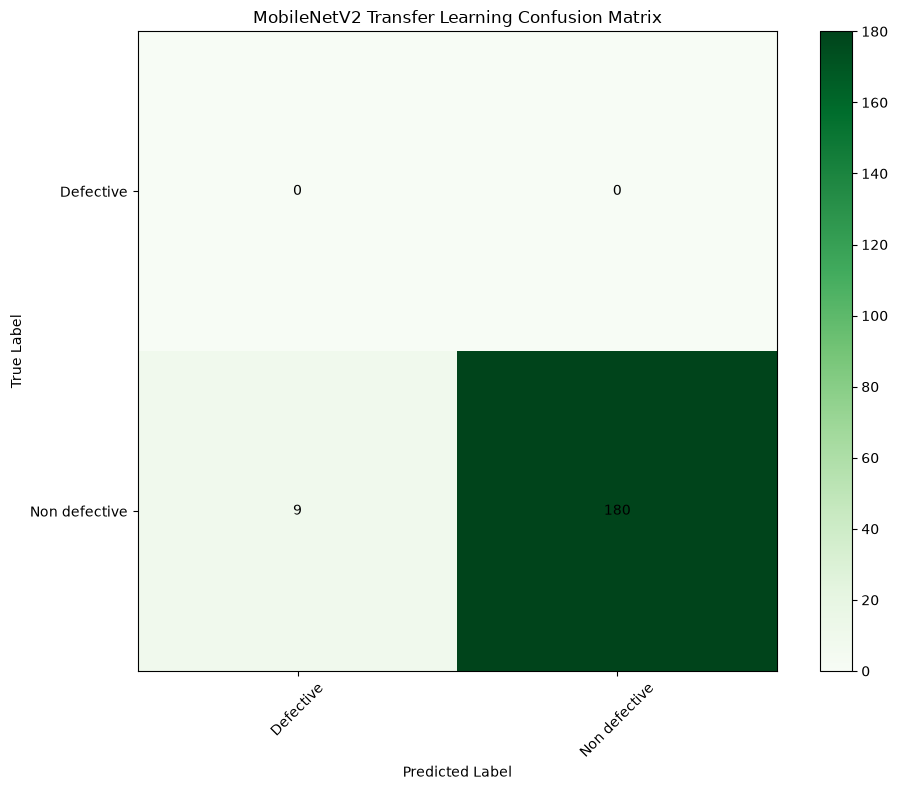

In [11]:
# Generate Transfer Learning confusion matrix

transfer_cm = confusion_matrix(y_true, transfer_predictions)

plt.figure(figsize=(10, 8))
plt.imshow(transfer_cm, cmap="Greens")
plt.title("MobileNetV2 Transfer Learning Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks(range(len(class_names)), class_names, rotation=45)
plt.yticks(range(len(class_names)), class_names)

for i in range(len(class_names)):
    for j in range(len(class_names)):
        plt.text(j, i, transfer_cm[i, j], ha="center", va="center")

plt.colorbar()
plt.tight_layout()
plt.show()

## Inference
The MobileNetV2 transfer learning confusion matrix was analyzed to identify correctly classified and incorrectly classified railway defect images. The matrix helps evaluate class-level prediction performance and compare the classification behavior of the transfer learning model against the CNN model.


## 9. Comparative Performance Analysis

In [12]:
# Compare both models using evaluation metrics

import pandas as pd

comparison_df = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score"],
    "CNN Model": [
        cnn_accuracy,
        cnn_precision,
        cnn_recall,
        cnn_f1
    ],
    "Transfer Learning": [
        transfer_accuracy,
        transfer_precision,
        transfer_recall,
        transfer_f1
    ]
})

print("MODEL PERFORMANCE COMPARISON")
display(comparison_df.round(4))

MODEL PERFORMANCE COMPARISON


,Metric,CNN Model,Transfer Learning
0,Accuracy,0.7407,0.9524
1,Precision,1.0000,1.0000
2,Recall,0.7407,0.9524
3,F1-Score,0.8511,0.9756


## Inference
A comparative performance table was created to evaluate the CNN and MobileNetV2 transfer learning models based on accuracy, precision, recall, and F1-score. The comparison helps identify the model with stronger overall classification performance.

## 9.2 — Performance Comparison Visualization

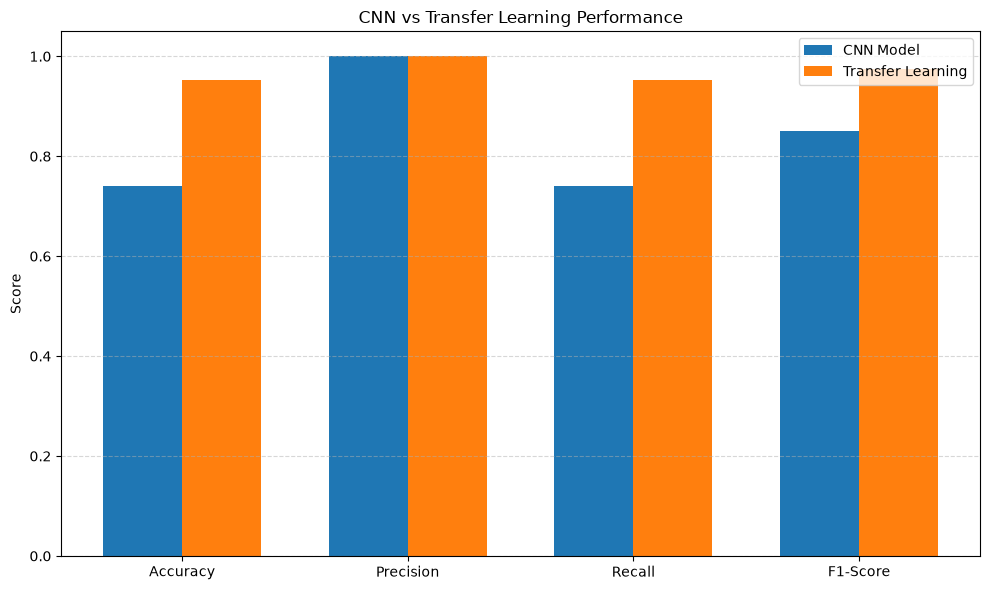

In [13]:
# Visual comparison of model performance

metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]

cnn_values = [cnn_accuracy, cnn_precision, cnn_recall, cnn_f1]
transfer_values = [
    transfer_accuracy,
    transfer_precision,
    transfer_recall,
    transfer_f1
]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(x - width/2, cnn_values, width, label="CNN Model")
plt.bar(x + width/2, transfer_values, width, label="Transfer Learning")

plt.xticks(x, metrics)
plt.ylabel("Score")
plt.title("CNN vs Transfer Learning Performance")
plt.ylim(0, 1.05)
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

## Inference
The performance comparison chart visually represents the evaluation scores of the CNN and MobileNetV2 transfer learning models. The model with higher and more consistent accuracy, precision, recall, and F1-score demonstrates stronger classification performance on the evaluation dataset.

## 10. Best Model Selection

In [14]:
# Identify the best model based on weighted F1-score

if transfer_f1 > cnn_f1:
    best_model_name = "MobileNetV2 Transfer Learning"
    best_model_accuracy = transfer_accuracy
    best_model_f1 = transfer_f1
else:
    best_model_name = "CNN Model"
    best_model_accuracy = cnn_accuracy
    best_model_f1 = cnn_f1

print("=" * 60)
print("BEST MODEL SELECTION")
print("=" * 60)

print("Selected Model       :", best_model_name)
print(f"Accuracy            : {best_model_accuracy:.4f}")
print(f"Weighted F1-Score   : {best_model_f1:.4f}")

print("=" * 60)

BEST MODEL SELECTION
Selected Model       : MobileNetV2 Transfer Learning
Accuracy            : 0.9524
Weighted F1-Score   : 0.9756


## Inference
The best-performing model was selected by comparing the weighted F1-scores of the CNN and MobileNetV2 transfer learning models. The selected model provides the highest weighted F1-score among the evaluated models and is considered the preferred candidate for further deployment and railway defect prediction.

## 11. Saving the Model Evaluation Report

In [15]:
# Save model evaluation results

evaluation_report = {
    "CNN_Model": {
        "Accuracy": float(cnn_accuracy),
        "Precision": float(cnn_precision),
        "Recall": float(cnn_recall),
        "F1_Score": float(cnn_f1)
    },
    "Transfer_Learning_Model": {
        "Accuracy": float(transfer_accuracy),
        "Precision": float(transfer_precision),
        "Recall": float(transfer_recall),
        "F1_Score": float(transfer_f1)
    },
    "Best_Model": best_model_name,
    "Best_Model_Accuracy": float(best_model_accuracy),
    "Best_Model_F1_Score": float(best_model_f1)
}

EVALUATION_REPORT_PATH = ARTIFACTS_PATH / "evaluation_report.json"

with open(EVALUATION_REPORT_PATH, "w") as file:
    json.dump(evaluation_report, file, indent=4)

print("Evaluation report saved successfully!")
print("Report Path:", EVALUATION_REPORT_PATH)

Evaluation report saved successfully!
Report Path: c:\Users\shrey\Downloads\RAILWAY_DEFECT_DETECTION\Artifacts\evaluation_report.json


## Inference
The evaluation results of both models were stored in JSON format. The report includes accuracy, precision, recall, weighted F1-score, and the selected best model. This report can be reused for project documentation, model comparison, and deployment preparation.

## 12. Final Model Evaluation Summary

In [16]:
# Final project evaluation summary

print("=" * 65)
print("RAILWAY DEFECT DETECTION - FINAL MODEL EVALUATION")
print("=" * 65)

print("\nCNN MODEL")
print("-" * 40)
print(f"Accuracy  : {cnn_accuracy:.4f}")
print(f"Precision : {cnn_precision:.4f}")
print(f"Recall    : {cnn_recall:.4f}")
print(f"F1-Score  : {cnn_f1:.4f}")

print("\nTRANSFER LEARNING MODEL")
print("-" * 40)
print(f"Accuracy  : {transfer_accuracy:.4f}")
print(f"Precision : {transfer_precision:.4f}")
print(f"Recall    : {transfer_recall:.4f}")
print(f"F1-Score  : {transfer_f1:.4f}")

print("\nBEST MODEL")
print("-" * 40)
print("Selected Model:", best_model_name)
print(f"Accuracy      : {best_model_accuracy:.4f}")
print(f"F1-Score      : {best_model_f1:.4f}")

print("\nEvaluation Report:", EVALUATION_REPORT_PATH)

print("=" * 65)
print("MODEL EVALUATION COMPLETED SUCCESSFULLY!")
print("=" * 65)

RAILWAY DEFECT DETECTION - FINAL MODEL EVALUATION

CNN MODEL
----------------------------------------
Accuracy  : 0.7407
Precision : 1.0000
Recall    : 0.7407
F1-Score  : 0.8511

TRANSFER LEARNING MODEL
----------------------------------------
Accuracy  : 0.9524
Precision : 1.0000
Recall    : 0.9524
F1-Score  : 0.9756

BEST MODEL
----------------------------------------
Selected Model: MobileNetV2 Transfer Learning
Accuracy      : 0.9524
F1-Score      : 0.9756

Evaluation Report: c:\Users\shrey\Downloads\RAILWAY_DEFECT_DETECTION\Artifacts\evaluation_report.json
MODEL EVALUATION COMPLETED SUCCESSFULLY!


## Inference
The final evaluation compared the CNN model trained from scratch and the MobileNetV2 transfer learning model. Both models were assessed using accuracy, precision, recall, and F1-score. The best model was selected based on weighted F1-score, and the evaluation report was saved for future use.